# Evaluate Cache

Does the cache let the model recall a place it left more than `H` steps ago?
Every revisit event (`H < N <= 4H`) is scored three ways, identical except for the bank:

- **none** -- no cache
- **random** -- same snapshots, offsets permuted (control: extra tokens, no correct memory)
- **matched** -- each snapshot with its true egocentric offset

The bank is built exactly as in training (`WorldModelDataset._cache_stores`) from true frames.

In [10]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))

import glob, random
import numpy as np
import torch
from IPython.display import Image, display

from src.cache.cache import Cache
from src.models.tokenizer import Tokenizer
from src.models.world_model import ACTION_DIM, COND_DIM, WorldModel
from src.utils.revisits import find_revisit_events
from src.utils.viz import save_path_strip, save_side_by_side_video

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
R_NEAR = 0.5      # "the bank holds this place" = a snapshot within this distance

tok_ckpt = torch.load("../checkpoints/tokenizer/latest.pt", map_location=DEVICE, weights_only=False)
tokenizer = Tokenizer().to(DEVICE).eval()
tokenizer.load_state_dict(tok_ckpt["model"])

wm_ckpt = torch.load("../checkpoints/worldmodel_cache_v2/latest.pt", map_location=DEVICE, weights_only=False)
H, C = wm_ckpt["args"]["history"], wm_ckpt["args"]["cache_size"]
model = WorldModel(history=H, cache_size=C, vocab_size=256, d_model=256).to(DEVICE).eval()
model.load_state_dict(wm_ckpt["model"])
print(f"world model step {wm_ckpt['step']}  H={H}  C={C}")


def load(path):
    with np.load(path) as d:
        return (d["tokens"].astype(np.int64), d["action"].astype(np.float32),
                d["agent_pos"].astype(np.float32), d["agent_dir"].astype(np.float32))


def bank_stores(tokens, pos, dir_):
    """stores[t] = bank contents when predicting frame t (same as training)."""
    cache, stores = Cache(C), []
    for t in range(len(tokens)):
        if t >= H:
            w = slice(t - H, t + 1)
            cache.update(tokens[w], pos[w], dir_[w])
        stores.append(list(cache.store))
    return stores


def cache_view(store, pos, dir_, mode, rng):
    """-> (tokens, cond, mask) batched on DEVICE, or Nones for mode='none'."""
    if mode == "none":
        return None, None, None
    if mode == "random":   # keep frames, permute which place each claims
        perm = rng.sample(range(len(store)), len(store))
        store = [(store[i][0], store[j][1], store[j][2]) for i, j in enumerate(perm)]
    c = Cache(C)
    c.store = store
    return [x.unsqueeze(0).to(DEVICE) for x in c.view(pos, dir_)]


def predict(tok_win, act_win, view):
    cond = torch.zeros(1, H + 1, COND_DIM, device=DEVICE)
    cond[0, :, :ACTION_DIM] = torch.from_numpy(act_win)
    return model.generate_last_frame(torch.from_numpy(tok_win)[None].to(DEVICE), cond, *view)[0].cpu().numpy()


def near(store, p):
    return bool(store) and min(np.linalg.norm(e[1] - p) for e in store) < R_NEAR

world model step 20000  H=16  C=8


## 1. Across many revisits: is the place in the bank, and does the model use it?

One-step prediction of the revisit frame `t2` from the **true** window. No rollout drift, so the
only thing that can differ between arms is the bank. `covered` = the bank held a snapshot
within `R_NEAR` of the agent at `t2`; only there can the cache help.

In [11]:
EPISODES = 40
EVENTS_PER_EPISODE = 10
SEED = None      # set an int to reproduce a run; None draws a fresh one
SEED = random.randrange(2**32) if SEED is None else SEED
rng = random.Random(SEED)
print(f"seed {SEED}")
ARMS = ("none", "random", "matched")

rows = []   # (path, t1, t2, n, covered, acc_none, acc_random, acc_matched)
with torch.no_grad():
    for path in rng.sample(sorted(glob.glob("../data/tokens/eval/*.npz")), EPISODES):
        tokens, actions, pos, dir_ = load(path)
        stores = bank_stores(tokens, pos, dir_)
        events = [e for e in find_revisit_events(pos) if H < e[2] <= 4 * H]
        for t1, t2, n in rng.sample(events, min(EVENTS_PER_EPISODE, len(events))):
            w = slice(t2 - H, t2 + 1)
            accs = [(predict(tokens[w], actions[w], cache_view(stores[t2], pos[t2], dir_[t2], m, rng))
                     == tokens[t2]).mean() for m in ARMS]
            rows.append((path, t1, t2, n, near(stores[t2], pos[t2]), *accs))

cov = np.array([r[4] for r in rows])
acc = np.array([r[5:] for r in rows])
print(f"{len(rows)} revisit events, bank covers {cov.mean():.0%} of them\n")
print(f"{'':<10}{'n':>5}" + "".join(f"{m:>9}" for m in ARMS))
for name, sel in [("covered", cov), ("uncovered", ~cov)]:
    print(f"{name:<10}{sel.sum():>5}" + "".join(f"{a:>9.3f}" for a in acc[sel].mean(0)))

a = acc[cov].mean(0)
print(f"\ncovered: matched - none = {a[2]-a[0]:+.3f}   matched - random = {a[2]-a[1]:+.3f}")

seed 195718653
400 revisit events, bank covers 68% of them

              n     none   random  matched
covered     270    0.189    0.185    0.187
uncovered   130    0.188    0.186    0.182

covered: matched - none = -0.002   matched - random = +0.002


## 2. One covered revisit, short rollout

Open-loop from `ROLL` steps before `t2` (true actions, bank of true frames, re-viewed every
step). Kept short on purpose: deep rollouts hit the accuracy floor and all arms read 0.

20220920T140247-1000.npz: t1=174 t2=198 N=24
  none     per-step acc: 0.19 0.19 0.19 0.38 0.00 0.06 0.00 0.12 0.12
  random   per-step acc: 0.19 0.19 0.19 0.38 0.06 0.19 0.00 0.06 0.12
  matched  per-step acc: 0.19 0.19 0.12 0.44 0.06 0.00 0.00 0.06 0.00


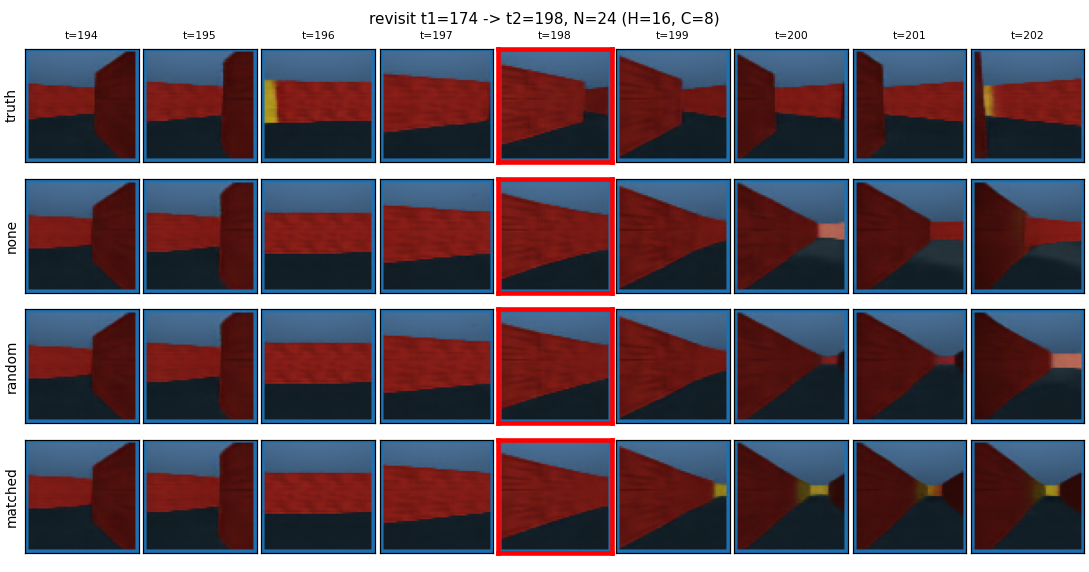

In [12]:
ROLL = 4          # open-loop steps before (and after) t2
FPS = 4

path, t1, t2, n = rng.choice([r[:4] for r in rows if r[4]])
tokens, actions, pos, dir_ = load(path)
stores = bank_stores(tokens, pos, dir_)
cols = list(range(t2 - ROLL, t2 + ROLL + 1))


def rollout(mode, rng):
    roll = tokens.copy()
    with torch.no_grad():
        for t in cols:
            w = slice(t - H, t + 1)
            roll[t] = predict(roll[w], actions[w], cache_view(stores[t], pos[t], dir_[t], mode, rng))
    return roll[cols]


rolls = {m: rollout(m, random.Random(0)) for m in ARMS}
print(f"{os.path.basename(path)}: t1={t1} t2={t2} N={n}")
for m in ARMS:
    print(f"  {m:<8} per-step acc: " + " ".join(f"{x:.2f}" for x in (rolls[m] == tokens[cols]).mean(1)))

with torch.no_grad():
    dec = lambda x: tokenizer.decode_indices(torch.from_numpy(x).to(DEVICE)).cpu()
    imgs = {"truth": dec(tokens[cols]), **{m: dec(rolls[m]) for m in ARMS}}

tag = f"{os.path.basename(path)[:-4]}_t2{t2}_N{n}"
os.makedirs("../outputs/worldmodel_cache", exist_ok=True)
strip = f"../outputs/worldmodel_cache/strip_{tag}.png"
save_path_strip(list(imgs.values()), strip, list(imgs.keys()),
                col_labels=[f"t={t}" for t in cols], highlight_col=ROLL,
                title=f"revisit t1={t1} -> t2={t2}, N={n} (H={H}, C={C})")
save_side_by_side_video(imgs["none"], imgs["matched"],
                        f"../outputs/worldmodel_cache/{tag}_none_vs_matched.mp4",
                        left_label="no cache", right_label="matched cache", fps=FPS)
display(Image(filename=strip))